In [1]:
import os, json, csv, hashlib, random
from collections import Counter
import numpy as np
from PIL import Image
import imagehash
import matplotlib.pyplot as plt

try:
    from tqdm import tqdm
except ImportError:
    def tqdm(x, **k): return x

ROOT = "archive"
SPLIT_JSON = "checkpoint_VIT-1/vit_b16-1_fold_splits_20260909_090705.json"
USE_JSON = False
SEED = 42
TEST_FRAC = 0.10
N_FOLDS = 5

COS_T = 0.84
HAM_T = 6

IMG_SIZE = 384
RESIZE_SIZE = 420
BATCH = 32
NUM_WORKERS = 0
OUT_DIR = "near_dup_report"
os.makedirs(OUT_DIR, exist_ok=True)

## 1. split

In [2]:
def class_of(p):
    try:
        return os.path.relpath(os.path.normpath(p), os.path.normpath(ROOT)).split(os.sep)[0]
    except ValueError:
        return os.path.basename(os.path.dirname(p))

def load_split():
    if USE_JSON and os.path.exists(SPLIT_JSON):
        with open(SPLIT_JSON) as f:
            sp = json.load(f)
        test = list(sp["held_out_test_filepaths"])
        folds = [list(f["val_filepaths"]) for f in sp["folds"]]
        pool = [p for f in folds for p in f]
        fold_of = {p: i for i, f in enumerate(folds) for p in f}
        print("Split dimuat dari", SPLIT_JSON)
        return test, pool, fold_of

    from torchvision.datasets import ImageFolder
    from sklearn.model_selection import train_test_split, StratifiedKFold
    ds = ImageFolder(ROOT)
    paths = np.array([p for p, _ in ds.samples])
    y = np.array(ds.targets)
    idx = np.arange(len(paths))
    pool_idx, test_idx = train_test_split(idx, test_size=TEST_FRAC, stratify=y, random_state=SEED)
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    fold_of = {}
    for i, (_, va) in enumerate(skf.split(pool_idx, y[pool_idx])):
        for j in pool_idx[va]:
            fold_of[paths[j]] = i
    print("Split direkonstruksi dari ImageFolder, seed", SEED)
    return list(paths[test_idx]), list(paths[pool_idx]), fold_of

test_paths, pool_paths, fold_of = load_split()
print("Test:", len(test_paths), "| Pool:", len(pool_paths))
print("File tidak ditemukan:", len([p for p in test_paths + pool_paths if not os.path.exists(p)]))
assert len(set(test_paths) & set(pool_paths)) == 0, "Test dan pool beririsan, cek split"

Split direkonstruksi dari ImageFolder, seed 42
Test: 1438 | Pool: 12938
File tidak ditemukan: 0


## 2. pHash: jarak Hamming terkecil dari tiap gambar test ke pool

In [3]:
def phash_bits(p):
    with Image.open(p) as im:
        return imagehash.phash(im).hash.flatten()

test_bits = np.array([phash_bits(p) for p in tqdm(test_paths)])
pool_bits = np.array([phash_bits(p) for p in tqdm(pool_paths)])

ph_d = np.zeros(len(test_paths), dtype=int)
ph_j = np.zeros(len(test_paths), dtype=int)
for s in range(0, len(test_paths), 100):
    blk = test_bits[s:s+100]
    d = (blk[:, None, :] != pool_bits[None, :, :]).sum(2)
    ph_j[s:s+100] = d.argmin(1)
    ph_d[s:s+100] = d.min(1)

print("Gambar test dengan tetangga pool pada jarak Hamming <= t:")
for t in [0, 2, 4, 6, 8, 10]:
    print(f"  t={t:2d}: {(ph_d <= t).sum()}")

Gambar test dengan tetangga pool pada jarak Hamming <= t:
  t= 0: 0
  t= 2: 6
  t= 4: 9
  t= 6: 16
  t= 8: 21
  t=10: 38


## 3. Embedding ViT pretrained dan kemiripan kosinus

In [4]:
import torch, torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_encoder():
    m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_SWAG_E2E_V1)
    m.heads = nn.Identity()
    return m.to(dev).eval()

tf = transforms.Compose([
    transforms.Resize((RESIZE_SIZE, RESIZE_SIZE)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class PathDS(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return tf(Image.open(self.paths[i]).convert("RGB"))

@torch.no_grad()
def embed(paths, encoder):
    out = []
    for x in tqdm(DataLoader(PathDS(paths), batch_size=BATCH, num_workers=NUM_WORKERS)):
        with torch.autocast("cuda", enabled=(dev.type == "cuda")):
            z = encoder(x.to(dev))
        out.append(nn.functional.normalize(z.float(), dim=1).cpu())
    return torch.cat(out).numpy()

def cached_embed(name, paths, encoder):
    f = os.path.join(OUT_DIR, f"emb_{name}.npy")
    key = hashlib.md5("\n".join(paths).encode()).hexdigest()
    kf = f + ".key"
    if os.path.exists(f) and os.path.exists(kf) and open(kf).read() == key:
        return np.load(f)
    e = embed(paths, encoder)
    np.save(f, e)
    open(kf, "w").write(key)
    return e

encoder = build_encoder()
te = cached_embed("test", test_paths, encoder)
po = cached_embed("pool", pool_paths, encoder)

sims = te @ po.T
em_s = sims.max(1)
em_j = sims.argmax(1)

print("Distribusi kosinus tetangga terdekat (test ke pool):")
for q in [50, 90, 95, 99, 100]:
    print(f"  persentil {q:3d}: {np.percentile(em_s, q):.4f}")
print("\nJumlah gambar test dengan kosinus >= ambang:")
for t in [0.98, 0.96, 0.94, 0.92, 0.90, 0.88, 0.86, 0.84, 0.82]:
    print(f"  >= {t:.2f}: {(em_s >= t).sum()}")

with open(os.path.join(OUT_DIR, "embed_test_vs_pool.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["test_file", "pool_file", "cosine", "kelas_test", "kelas_pool"])
    for i in np.argsort(-em_s)[:500]:
        w.writerow([test_paths[i], pool_paths[em_j[i]], f"{em_s[i]:.4f}", class_of(test_paths[i]), class_of(pool_paths[em_j[i]])])

Distribusi kosinus tetangga terdekat (test ke pool):
  persentil  50: 0.7860
  persentil  90: 0.8943
  persentil  95: 0.9196
  persentil  99: 0.9579
  persentil 100: 0.9891

Jumlah gambar test dengan kosinus >= ambang:
  >= 0.98: 3
  >= 0.96: 13
  >= 0.94: 38
  >= 0.92: 71
  >= 0.90: 131
  >= 0.88: 202
  >= 0.86: 292
  >= 0.84: 380
  >= 0.82: 502


## 4. Tinjau visual

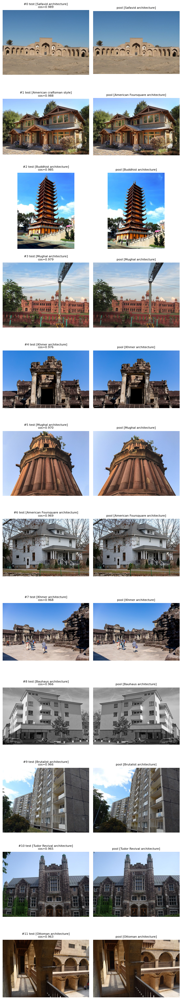

In [5]:
def show_pairs(order, left_paths, right_paths, score, label, start=0, n=12):
    sel = order[start:start+n]
    if len(sel) == 0:
        print("Tidak ada pasangan pada rentang ini")
        return
    fig, axes = plt.subplots(len(sel), 2, figsize=(7, 3.2 * len(sel)))
    if len(sel) == 1: axes = axes.reshape(1, 2)
    for r, i in enumerate(sel):
        a, b = left_paths[i], right_paths[i]
        for c, p in enumerate((a, b)):
            axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        axes[r, 0].set_title(f"#{start + r} test [{class_of(a)}]\n{label}={score[i]:.3f}", fontsize=8)
        axes[r, 1].set_title(f"pool [{class_of(b)}]", fontsize=8)
    plt.tight_layout(); plt.show()

pairs_right = [pool_paths[j] for j in em_j]
order_e = np.argsort(-em_s)
show_pairs(order_e, test_paths, pairs_right, em_s, "cos", start=0, n=12)

peringkat   0: cos = 0.9891
peringkat  12: cos = 0.9618
peringkat  24: cos = 0.9528
peringkat  36: cos = 0.9419
peringkat  48: cos = 0.9345
peringkat  60: cos = 0.9264
peringkat  80: cos = 0.9167
peringkat 100: cos = 0.9084
peringkat 130: cos = 0.9000
peringkat 200: cos = 0.8804
peringkat 300: cos = 0.8579
peringkat 380: cos = 0.8399


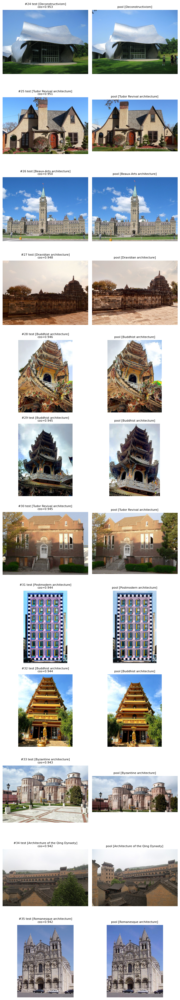

In [6]:
for r in [0, 12, 24, 36, 48, 60, 80, 100, 130, 200, 300, 380]:
    if r < len(order_e):
        print(f"peringkat {r:3d}: cos = {em_s[order_e[r]]:.4f}")
show_pairs(order_e, test_paths, pairs_right, em_s, "cos", start=24, n=12)

Rentang 0.92 sampai 0.94: 33 gambar test


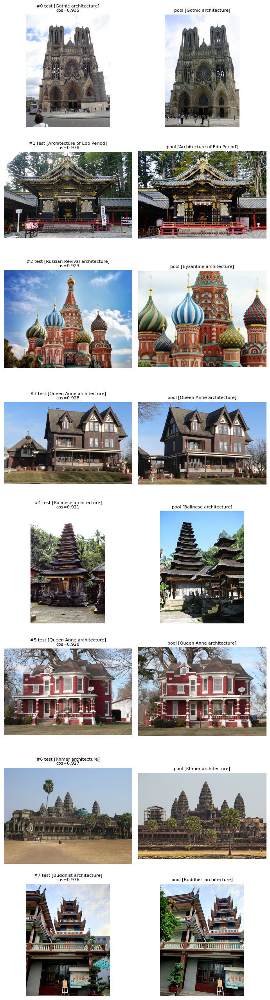

Rentang 0.90 sampai 0.92: 60 gambar test


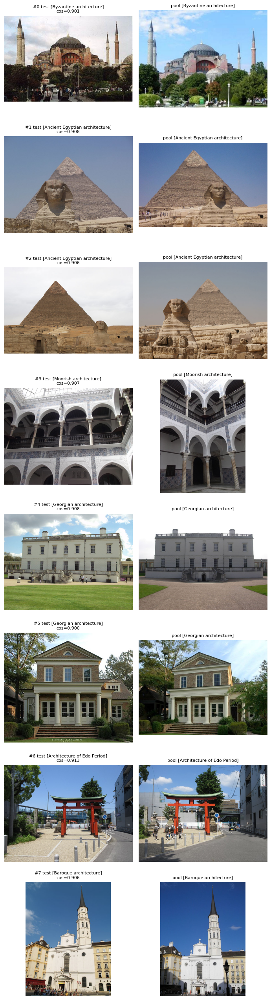

Rentang 0.88 sampai 0.90: 71 gambar test


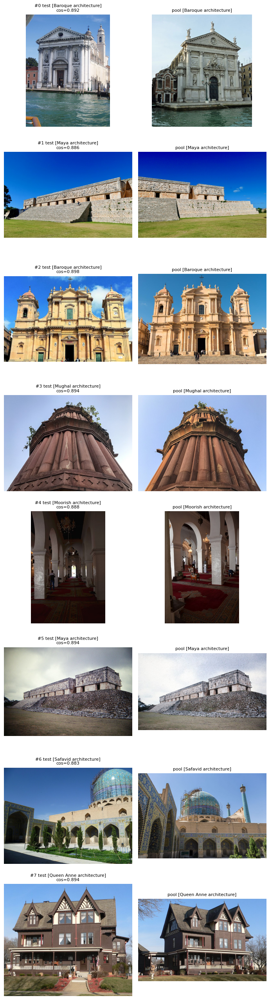

Rentang 0.86 sampai 0.88: 90 gambar test


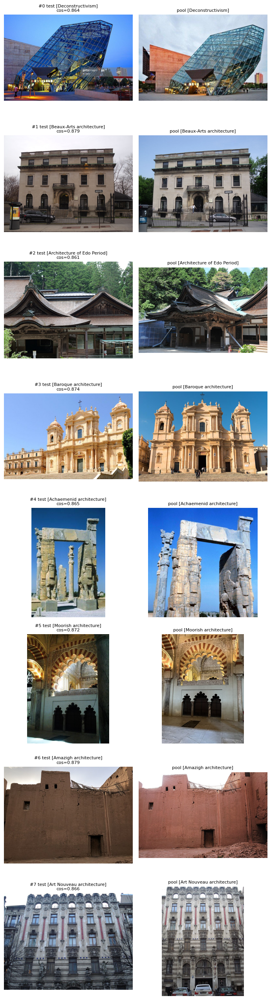

Rentang 0.84 sampai 0.86: 88 gambar test


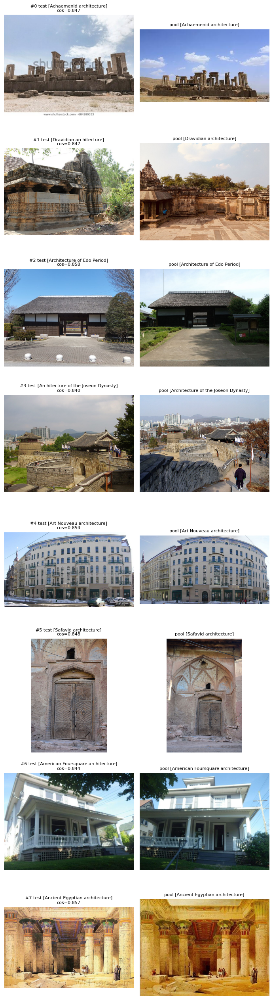

Rentang 0.82 sampai 0.84: 122 gambar test


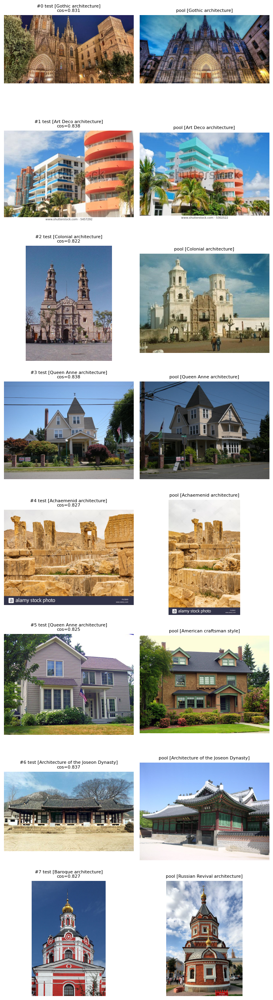

In [7]:
bands = [(0.92, 0.94), (0.90, 0.92), (0.88, 0.90), (0.86, 0.88), (0.84, 0.86), (0.82, 0.84)]
for lo, hi in bands:
    idx = np.where((em_s >= lo) & (em_s < hi))[0]
    print(f"Rentang {lo:.2f} sampai {hi:.2f}: {len(idx)} gambar test")
    if len(idx) == 0:
        continue
    pick = np.array(random.Random(0).sample(list(idx), min(8, len(idx))))
    show_pairs(pick, test_paths, pairs_right, em_s, "cos", start=0, n=len(pick))

## 5. Tandai gambar test yang bocor

In [8]:
flag_mask = (em_s >= COS_T) | (ph_d <= HAM_T)
flagged = set(np.array(test_paths)[flag_mask])
n_total, n_flag = len(test_paths), int(flag_mask.sum())
print(f"Ditandai: {n_flag} dari {n_total} ({n_flag / n_total * 100:.1f}%) | tersisa: {n_total - n_flag}")
print(f"  hanya lewat kosinus : {int(((em_s >= COS_T) & ~(ph_d <= HAM_T)).sum())}")
print(f"  hanya lewat pHash   : {int((~(em_s >= COS_T) & (ph_d <= HAM_T)).sum())}")
print(f"  keduanya            : {int(((em_s >= COS_T) & (ph_d <= HAM_T)).sum())}")

idx_flag = np.where(flag_mask)[0]
lintas = [i for i in idx_flag if class_of(test_paths[i]) != class_of(pool_paths[em_j[i]])]
print("Ditandai dengan tetangga terdekat (embedding) berkelas beda:", len(lintas))

with open(os.path.join(OUT_DIR, "flagged_test_files.json"), "w") as f:
    json.dump(sorted(flagged), f, indent=1)

c_all = Counter(class_of(p) for p in test_paths)
c_sisa = Counter(class_of(p) for p in test_paths if p not in flagged)
print("\nKelas dengan sisa gambar test terkecil:")
for k in sorted(c_all, key=lambda k: c_sisa[k])[:10]:
    print(f"  {k}: {c_all[k]} -> {c_sisa[k]}")

Ditandai: 380 dari 1438 (26.4%) | tersisa: 1058
  hanya lewat kosinus : 364
  hanya lewat pHash   : 0
  keduanya            : 16
Ditandai dengan tetangga terdekat (embedding) berkelas beda: 11

Kelas dengan sisa gambar test terkecil:
  Pueblo architecture: 7 -> 5
  Khmer architecture: 26 -> 9
  Architecture of Edo Period: 30 -> 10
  Moorish architecture: 22 -> 11
  Jain architecture: 11 -> 11
  Amazigh architecture: 15 -> 12
  Buddhist architecture: 22 -> 13
  Swahili architecture: 15 -> 13
  Architecture of the Joseon Dynasty: 25 -> 14
  Balinese architecture: 17 -> 14


## 6. Kebocoran antar fold di pool

In [9]:
FOLD_ARR = np.array([fold_of[p] for p in pool_paths])
nn_s = np.zeros(len(pool_paths)); nn_j = np.zeros(len(pool_paths), dtype=int)
for s in range(0, len(pool_paths), 500):
    blk = po[s:s+500] @ po.T
    blk[np.arange(blk.shape[0]), np.arange(s, s + blk.shape[0])] = -1
    nn_s[s:s+500] = blk.max(1); nn_j[s:s+500] = blk.argmax(1)

cross = FOLD_ARR != FOLD_ARR[nn_j]
cv_counts = {}
print("Gambar pool dengan tetangga terdekat di fold lain, kosinus >= ambang:")
for t in [COS_T, 0.90, 0.92, 0.94, 0.96, 0.98]:
    n = int(((nn_s >= t) & cross).sum())
    cv_counts[t] = n
    print(f"  >= {t:.2f}: {n} dari {len(pool_paths)} ({n / len(pool_paths) * 100:.1f}%)")

Gambar pool dengan tetangga terdekat di fold lain, kosinus >= ambang:
  >= 0.84: 2696 dari 12938 (20.8%)
  >= 0.90: 911 dari 12938 (7.0%)
  >= 0.92: 584 dari 12938 (4.5%)
  >= 0.94: 313 dari 12938 (2.4%)
  >= 0.96: 122 dari 12938 (0.9%)
  >= 0.98: 34 dari 12938 (0.3%)


## 7. Ringkasan angka

In [10]:
n_pool = len(pool_paths)
n_all = len(test_paths) + n_pool
print(f"Test asli                         : {n_total}")
print(f"Ditandai (dikeluarkan)            : {n_flag} ({n_flag / n_total * 100:.1f}%)")
print(f"Test bersih                       : {n_total - n_flag} ({(n_total - n_flag) / n_all * 100:.1f}% dari seluruh data)")
print(f"Ditandai berkelas beda dgn tetangga: {len(lintas)}")
print(f"Ambang                            : kosinus >= {COS_T}, Hamming <= {HAM_T}")
print(f"Pool dgn tetangga di fold lain (kosinus >= {COS_T}): {cv_counts[COS_T]} dari {n_pool} ({cv_counts[COS_T] / n_pool * 100:.1f}%)")

Test asli                         : 1438
Ditandai (dikeluarkan)            : 380 (26.4%)
Test bersih                       : 1058 (7.4% dari seluruh data)
Ditandai berkelas beda dgn tetangga: 11
Ambang                            : kosinus >= 0.84, Hamming <= 6
Pool dgn tetangga di fold lain (kosinus >= 0.84): 2696 dari 12938 (20.8%)
